In [11]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=14
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -52. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5. * nS 
g_AMPA_rec_E = 5. * nS 
g_AMPA_ext_I = 5. * nS
g_AMPA_rec_I = 5. * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800


#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0

#HSP
# tau_HSP = 20*second           
# alpha_HSP = 0.001            
# target_rate = 10*Hz
# tau_insert = 10 * second  
# tau_intern = 1 * second  

# tau_vm = 200*ms
# vm_record_dt = 10*ms

tau_HSP = 100*second           
alpha_HSP = 0.1            
target_rate = 10*Hz

tau_vm = 200*ms
vm_record_dt = 10*ms
tau_active = 200*ms
  

# rf_indices = [1,25,33,46,53,64,77,85,96]
center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.2   # X% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.1   # X% reduction of excitatory drive onto I
ALC_INC_GABA_E = 0.2   # X% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.1   # X% increase of inhibitory drive onto I



kill_mask = np.ones((n_input_rows, n_input_columns), dtype=np.float32)
# kill_mask[3, 3] = 0
# kill_mask[3, 4] = 0
# kill_mask[3, 5] = 0
# kill_mask[3, 6] = 0
# kill_mask[4, 3] = 0
# kill_mask[4, 4] = 0
# kill_mask[4, 5] = 0
# kill_mask[4, 6] = 0
# kill_mask[5, 3] = 0
# kill_mask[5, 4] = 0
# kill_mask[5, 5] = 0
# kill_mask[5, 6] = 0



def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    #orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])
    orientation = 'diagonal'

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=60):
    filtered_img = abs(filtered_img)
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate
    rates = clip(rates,5,60) * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol,target_rate = 10*Hz):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp * (1 + ALC_INC_GABA_E * alc) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (1 - ALC_INC_GABA_I * alc) * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz
    # HSP scaling variables (dimensionless)
    dx_postE / dt = -x_postE / tau_HSP : 1
    r_postE = x_postE / tau_HSP : Hz
    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((r_postE -target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((target_rate - r_postE)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((r_postE - target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((target_rate - r_postE)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 1000*second   
    P_E.tau_int_AMPA_E = 30*second    
    P_E.tau_ins_GABA_E = 1000*second   
    P_E.tau_int_GABA_E = 30*second   

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3   
    P_I.tau_ins_AMPA_I = 1000*second   
    P_I.tau_int_AMPA_I = 30*second    
    P_I.tau_ins_GABA_I = 1000*second   
    P_I.tau_int_GABA_I = 30*second



    P_E.t_on  = 100*second
    P_E.t_off = 700*second#700*second#1000*second
    P_I.t_on  = 100*second
    P_I.t_off = 700*second#700*second#1000*second

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(False)  

        rf_size = 3  
        half_rf = rf_size // 2


        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
                

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre='s_AMPA_ext += w', method='euler', name='PG_E')
        C_PG_E.connect(False)  
        rf_size = 3  
        half_rf = rf_size // 2
        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre='s_AMPA += w', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        x_postE_post += 1.0 / 2
        ''', method='euler', name='E_I')
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', #model='vm_pop_post = v_pre / N_pre : volt (summed)'
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=vm_record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=10*ms, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=10*ms, name='act_mon_I')


    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_img(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(1000*ms)


def show_img_mask(net, index,show_time=1000*ms):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    filtered *= kill_mask
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(show_time)



def train(N_train,alcohol,target_rate = 10*Hz):
    net = build_network(True,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_train): 
        show_img(net, index = i)
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net


def test(N_test,alcohol,show_time = 1000*ms,target_rate = 10*Hz):
    net = build_network(False,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_test):
        show_img_mask(net, index=i, show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_efe184f16d0f8aefbc30cc680c3537da' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_efe184f16d0f8aefbc30cc680c3537da.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_efe184f16d0f8aefbc30cc680c3537da.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_efe184f16d0f8aefbc30cc680c3537da.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
Tested image 1/1


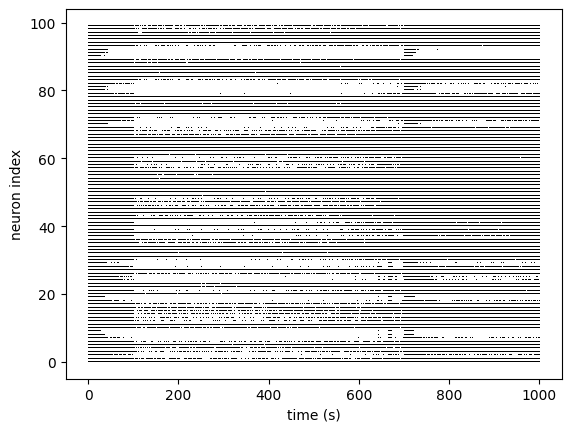

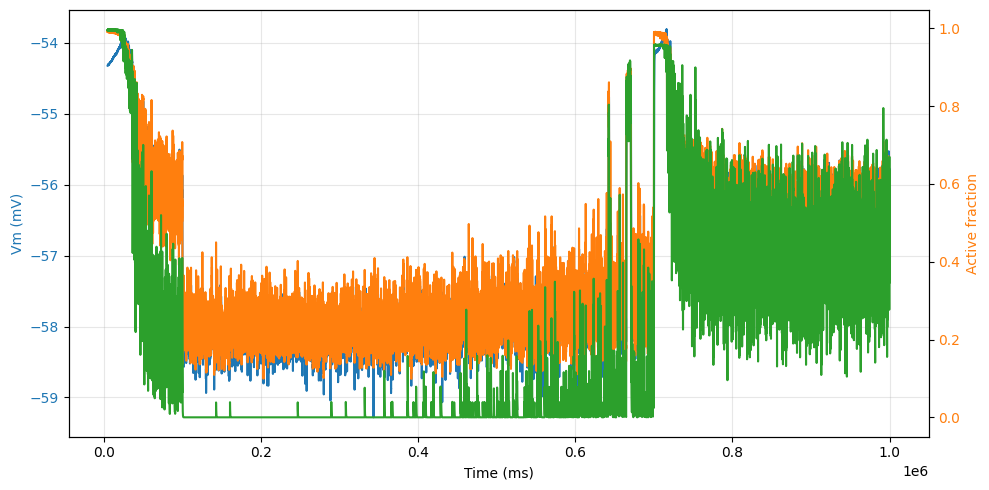

In [12]:
start_scope()
defaultclock.dt = 250 * us
net = test(1,alcohol=False,show_time=1000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

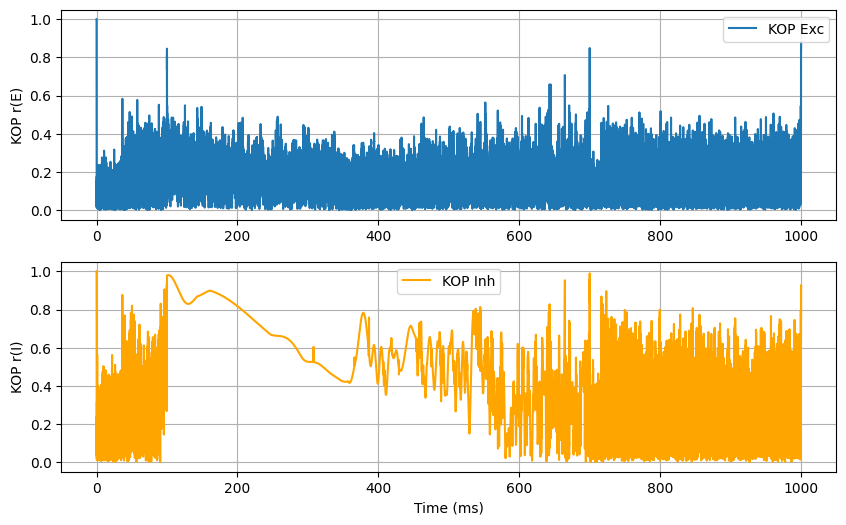

In [13]:
plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.plot(t_grid, rE, label='KOP Exc')
plt.ylabel(f'KOP r(E)')
plt.legend()
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(t_grid, rI, color='orange', label='KOP Inh')
plt.xlabel('Time (ms)')
plt.ylabel(f'KOP r(I)')
plt.legend()
plt.grid(True)